In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.DROPOUT_P,
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


opti = [
    # ("SGD", 0.001),
    # ("SGD", 0.01),
    ("SGD", 0.1),
    # ("Adam", 0.0001),
    # ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    # 64,
    100,
    # 256,
    # 512
]

neurons = [
    # (64, 32),
    (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
     0,
    0.025,
    0.05,
    0.1
    # 0.2,
    #  0.5
]



#i choose  SGD-0.1/128-64/B100/D0
def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 4




Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 52.38 seconds

Peak GPU memory: 18.47 MB

Test CEL: 0.38093
Test accuracy: 87.78%

----------------- SGD-0.1/128-64/B100/D0 -----------------


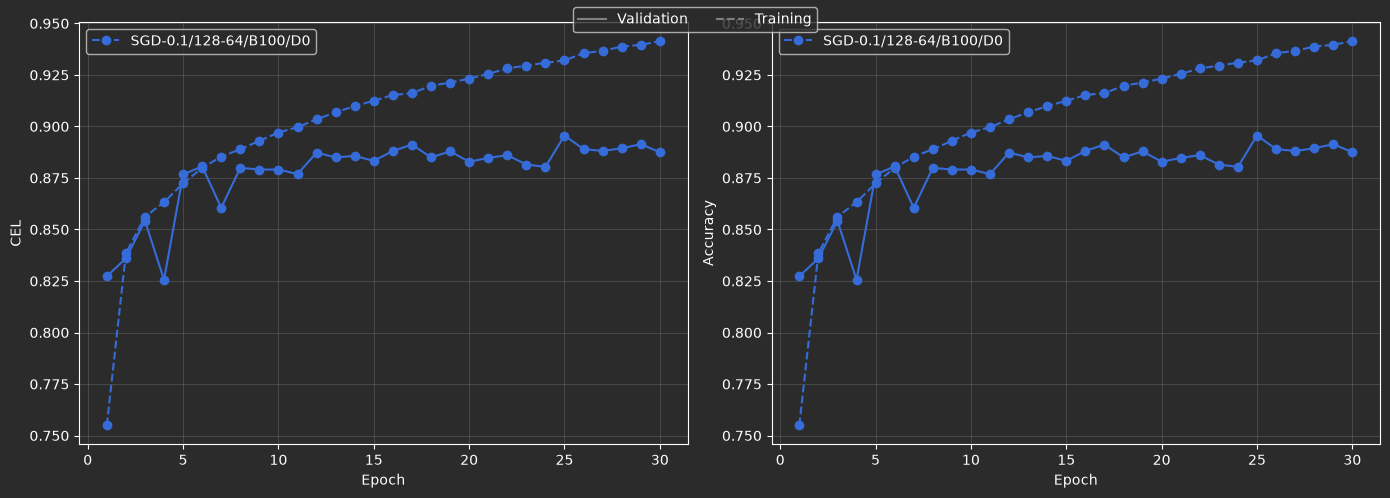

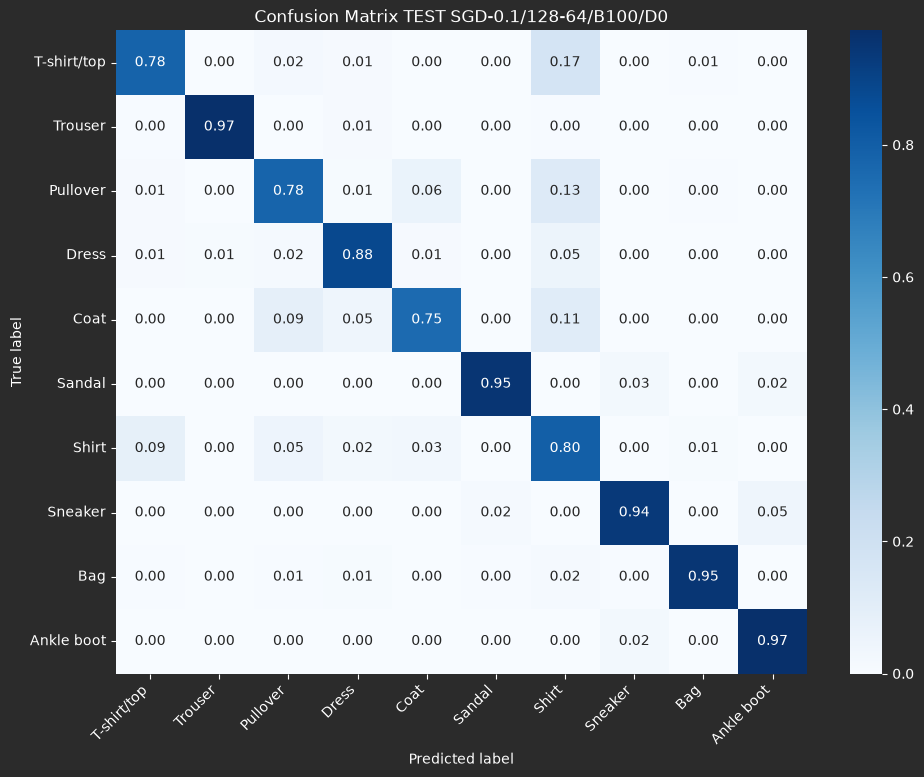

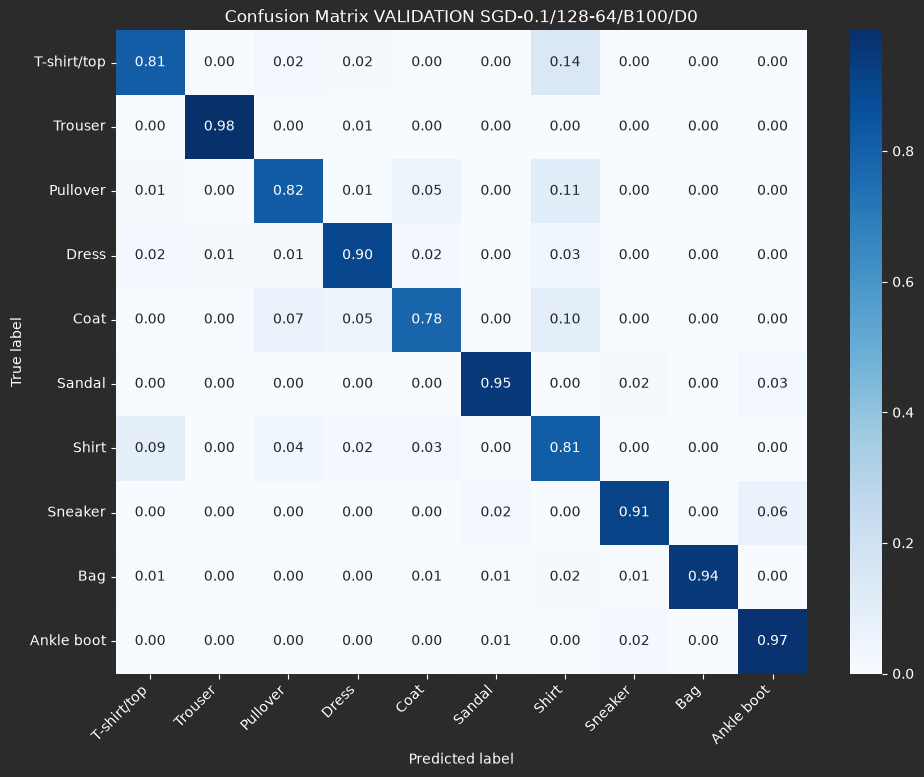


Optimizador: SGD
Dropout: 0.025

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.025 | Batch size -> 100
Training time: 51.07 seconds

Peak GPU memory: 19.30 MB

Test CEL: 0.35951
Test accuracy: 88.22%

----------------- SGD-0.1/128-64/B100/D0.025 -----------------


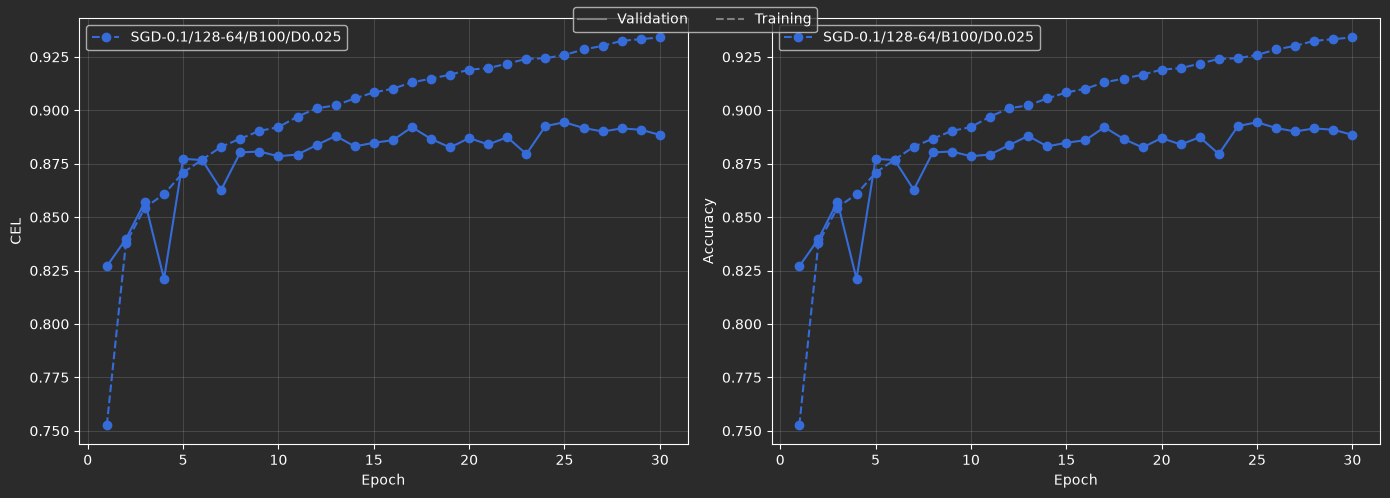

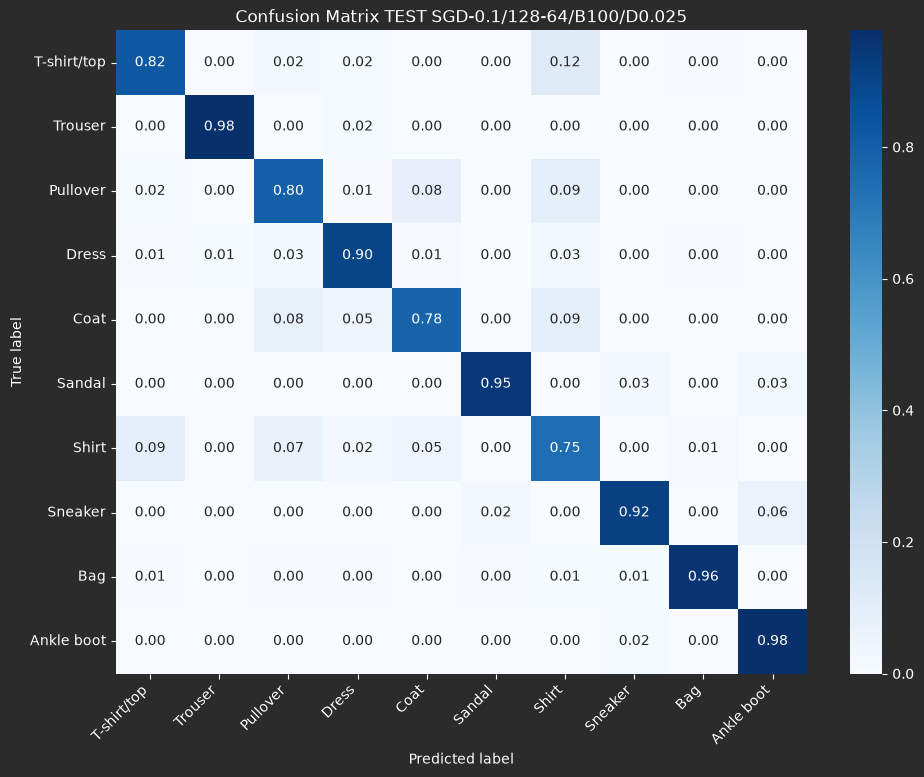

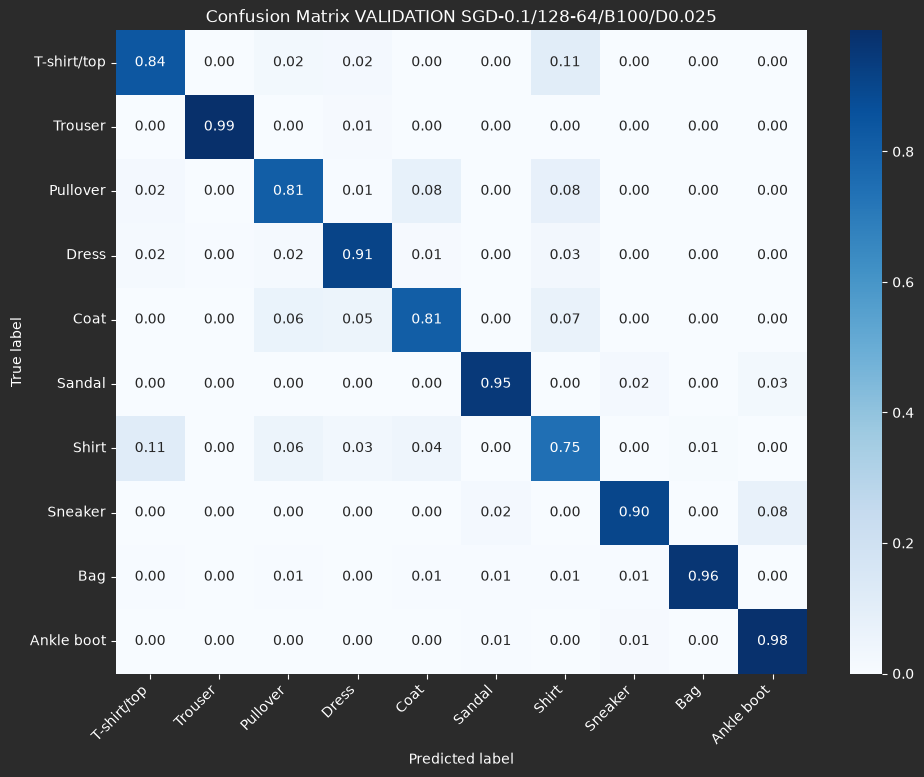


Optimizador: SGD
Dropout: 0.05

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.05 | Batch size -> 100
Training time: 52.06 seconds

Peak GPU memory: 20.14 MB

Test CEL: 0.34762
Test accuracy: 88.66%

----------------- SGD-0.1/128-64/B100/D0.05 -----------------


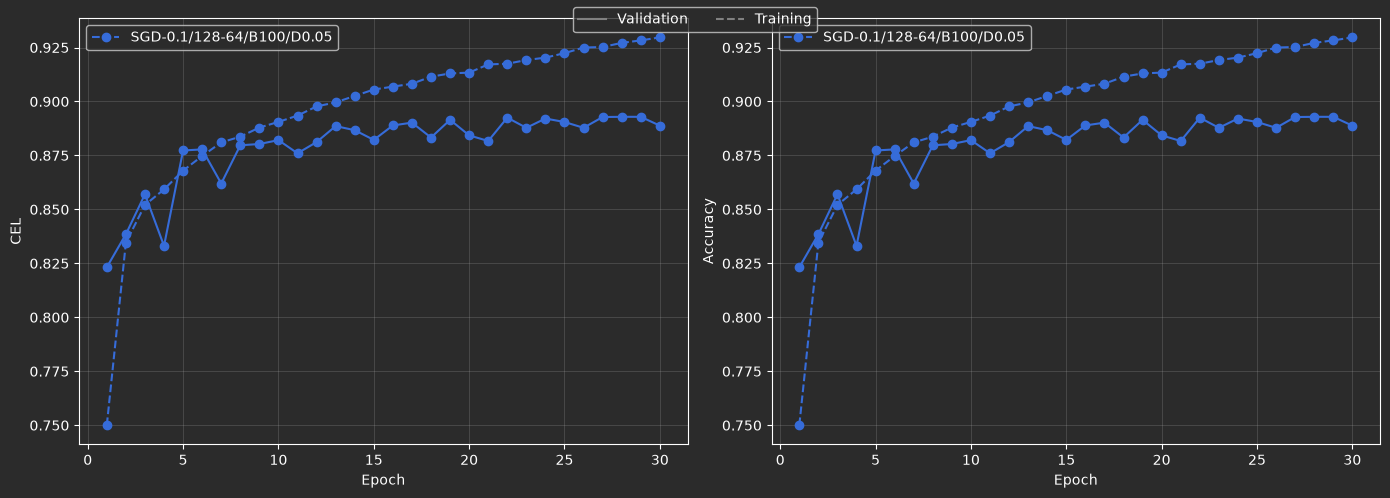

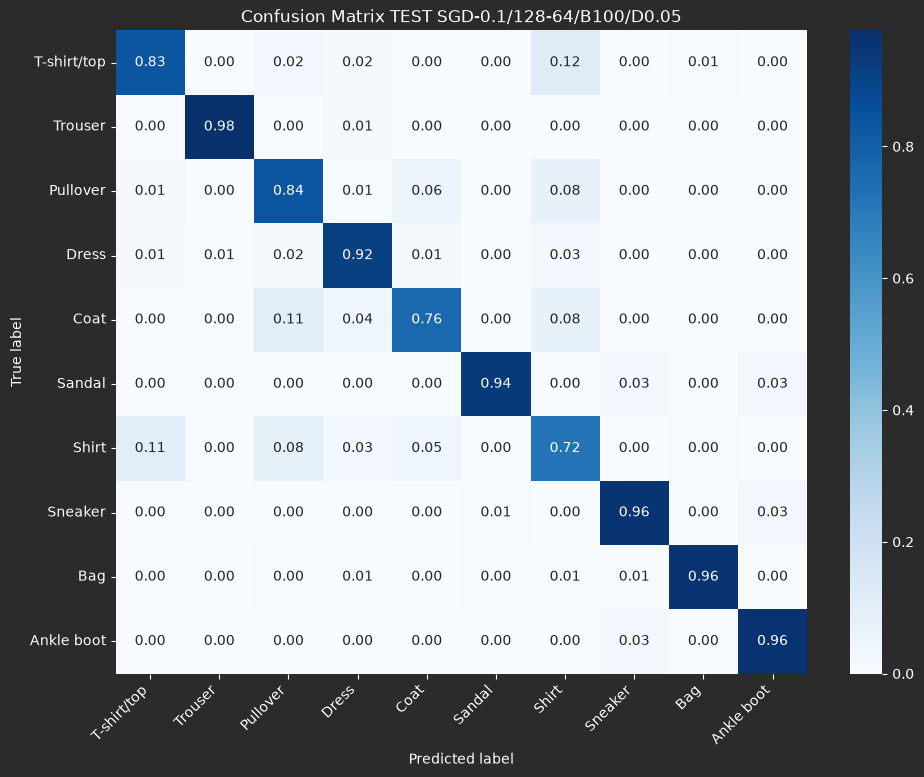

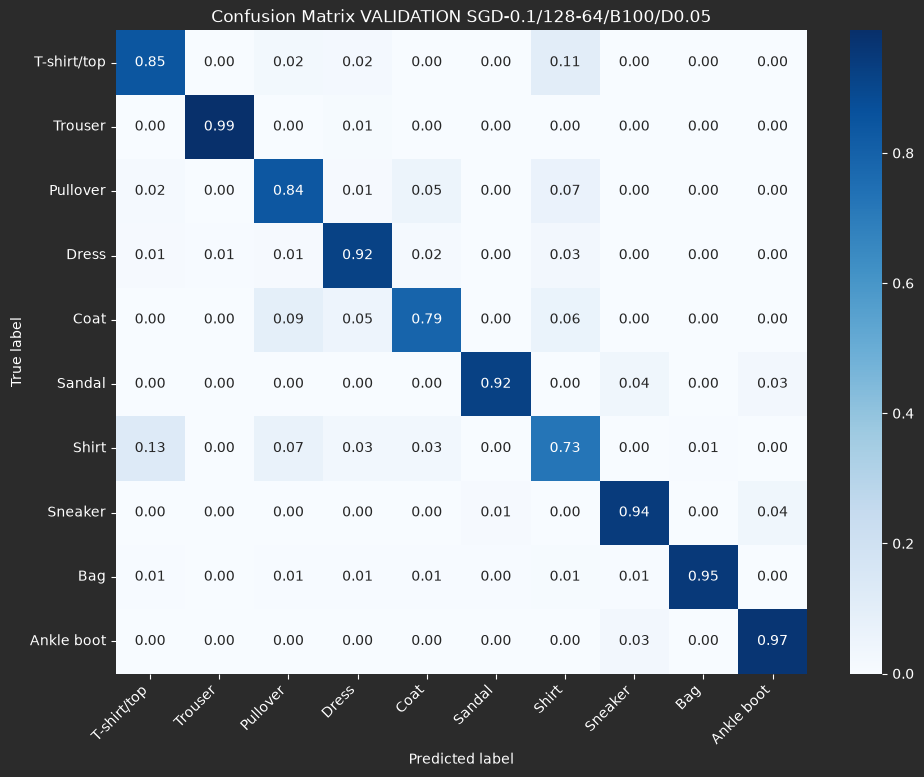


Optimizador: SGD
Dropout: 0.1

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.1 | Batch size -> 100
Training time: 51.52 seconds

Peak GPU memory: 20.98 MB

Test CEL: 0.32964
Test accuracy: 88.80%

----------------- SGD-0.1/128-64/B100/D0.1 -----------------


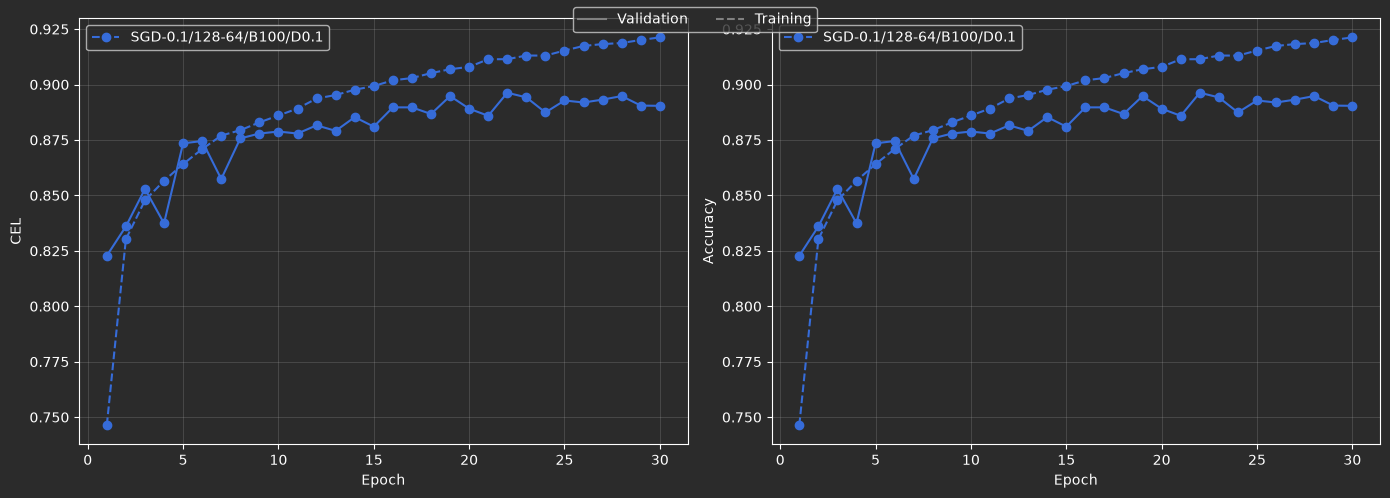

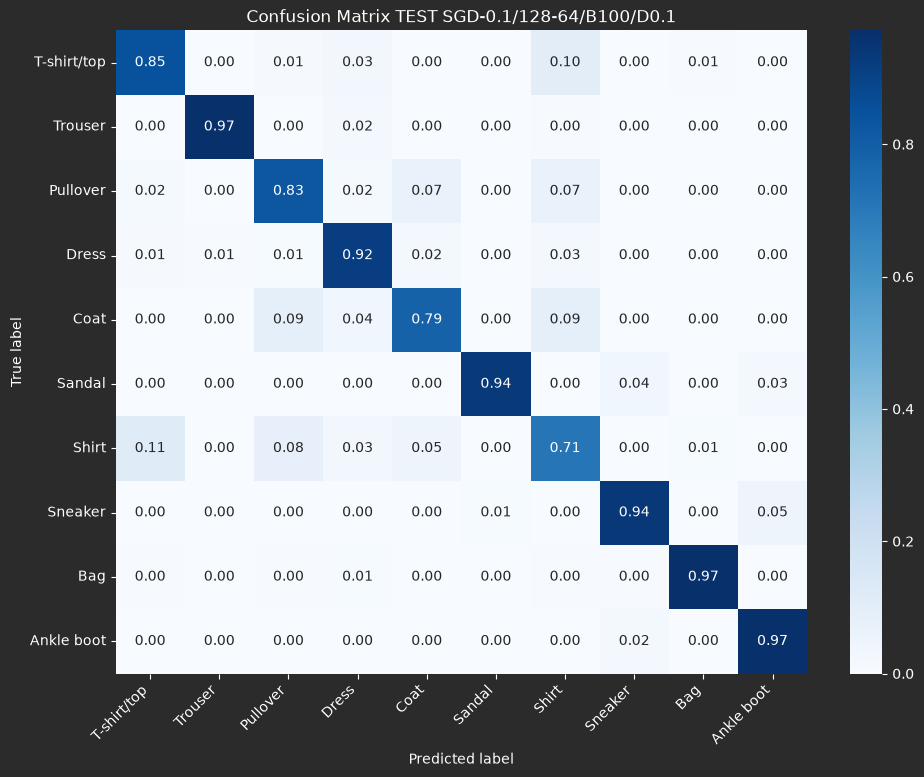

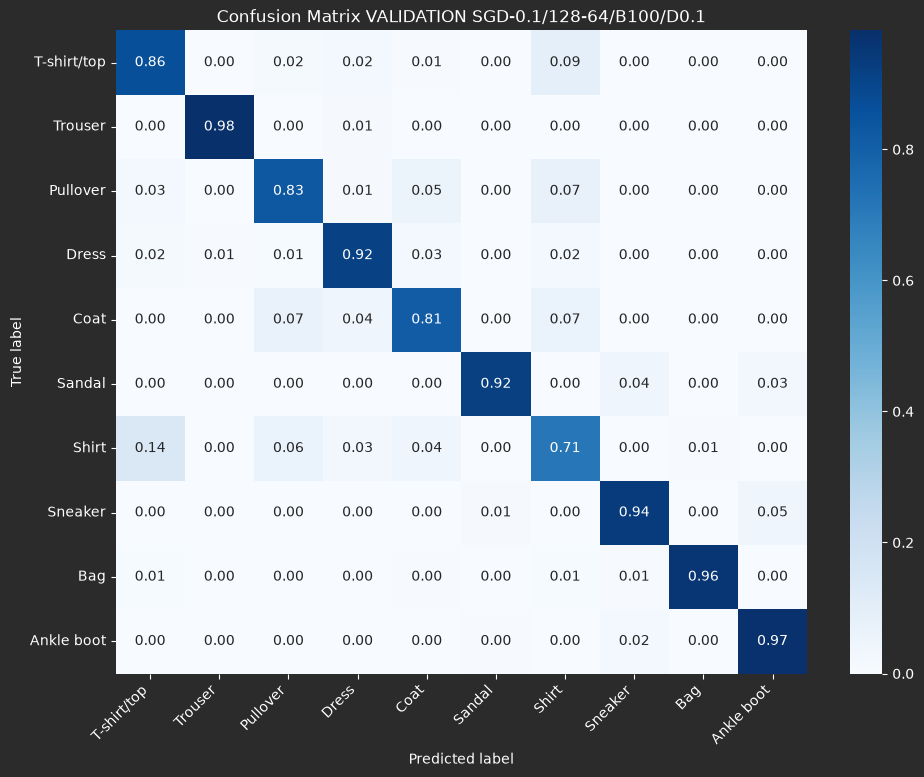

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: (0,):-----------------------------------

----------------- SGD-0.1/128-64/B100/D0 -----------------


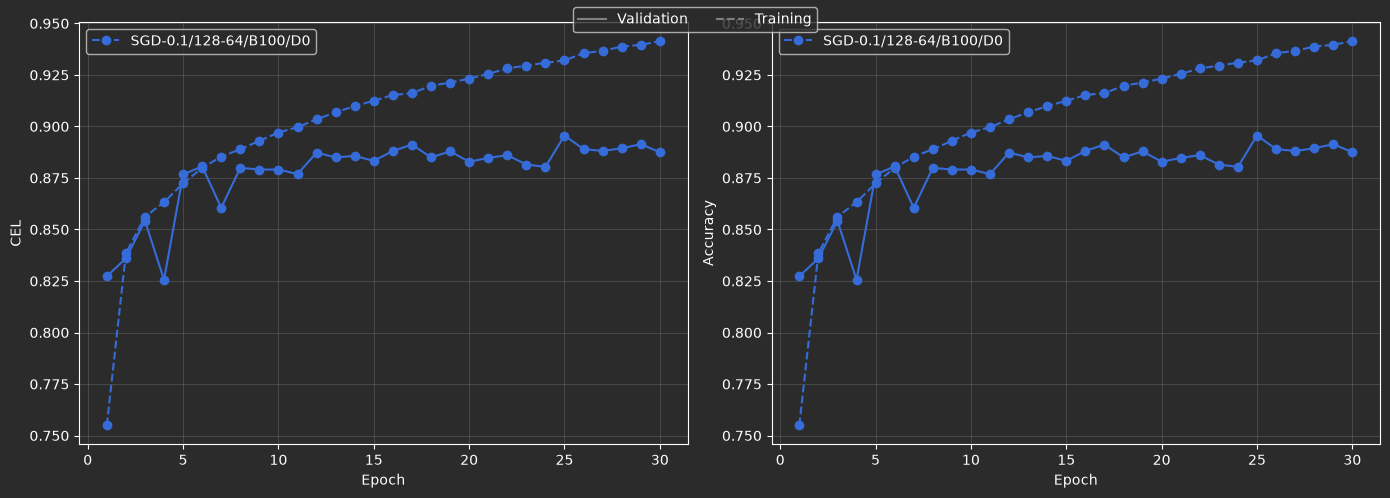

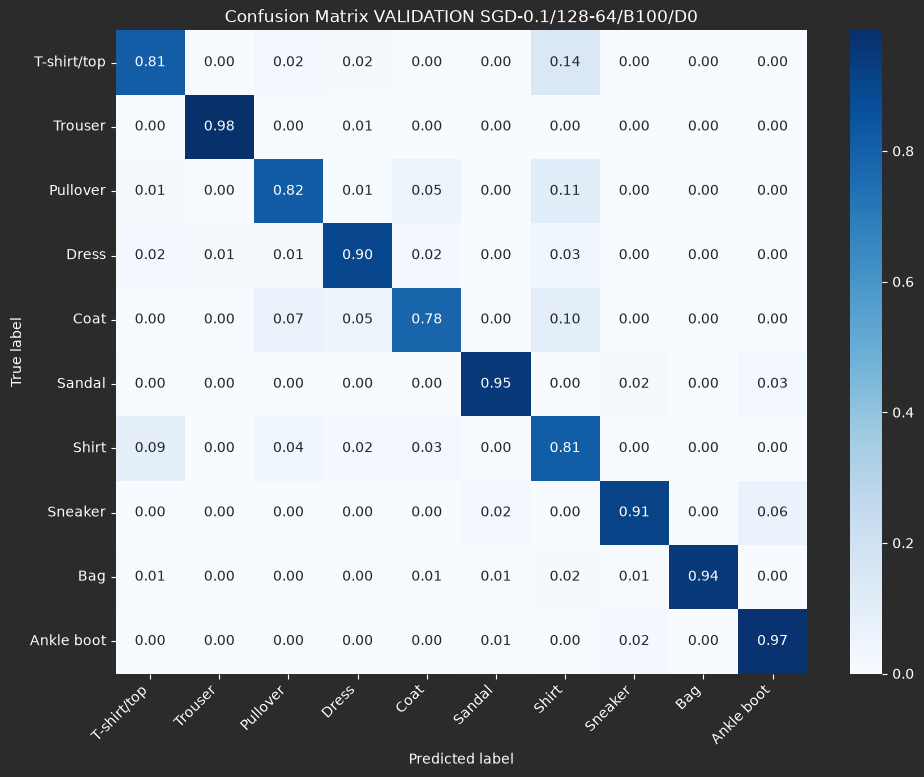

                       Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
SGD-0.1/128-64/B100/D0      0.158      0.343      0.941      0.887     0.878             Coat (75.50%)              Coat (78.13%)                   0.755                    0.781  0.054             0.317              0.251

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0: 0.8778
Max Valid Accu     -> SGD-0.1/128-64/B100/D0: 0.8875
Best Test Worst-Class Recall -> SGD-0.1/128-64/B100/D0: Coat (75.50%)
Best Valid Worst-Class Recall -> SGD-0.1/128-64/B100/D0: Coat (78.13%)
Min Test CM Deviation  -> SGD-0.1/128-64/B100/D0: 0.3166
Min Valid CM Deviation -> SGD-0.1/128-64/B100/D0: 0.2511
Min abs Generalization Gap -> SGD-0.1/128-64/B100/D0: 0.053939998149871826
Max abs Generalization Gap -> SGD-0.1/128-64/B100/D0: 0.053939998149871826

----------------

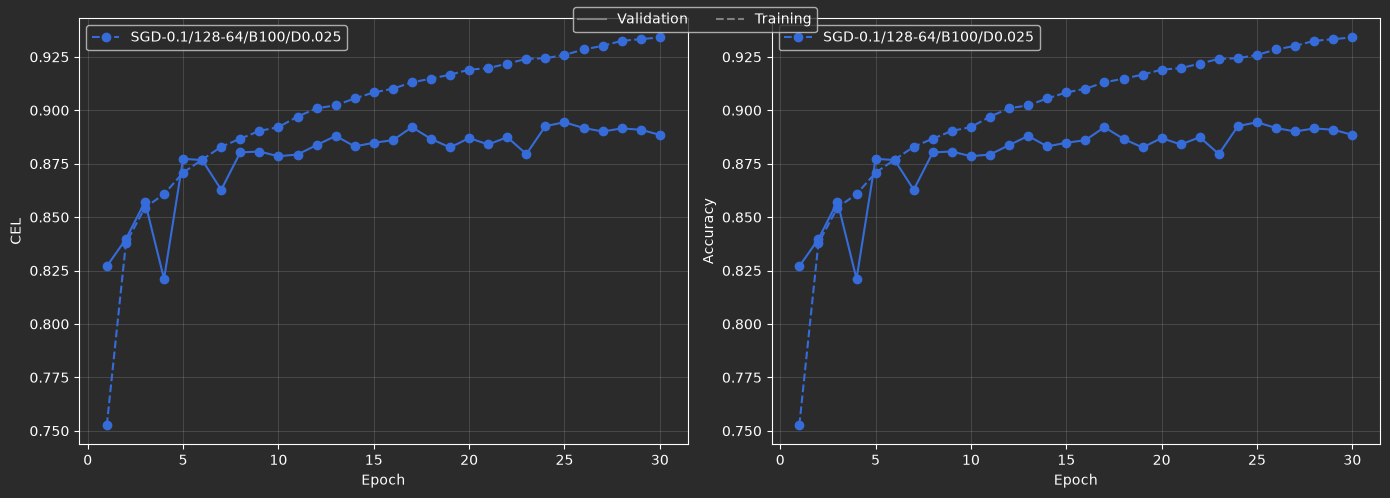

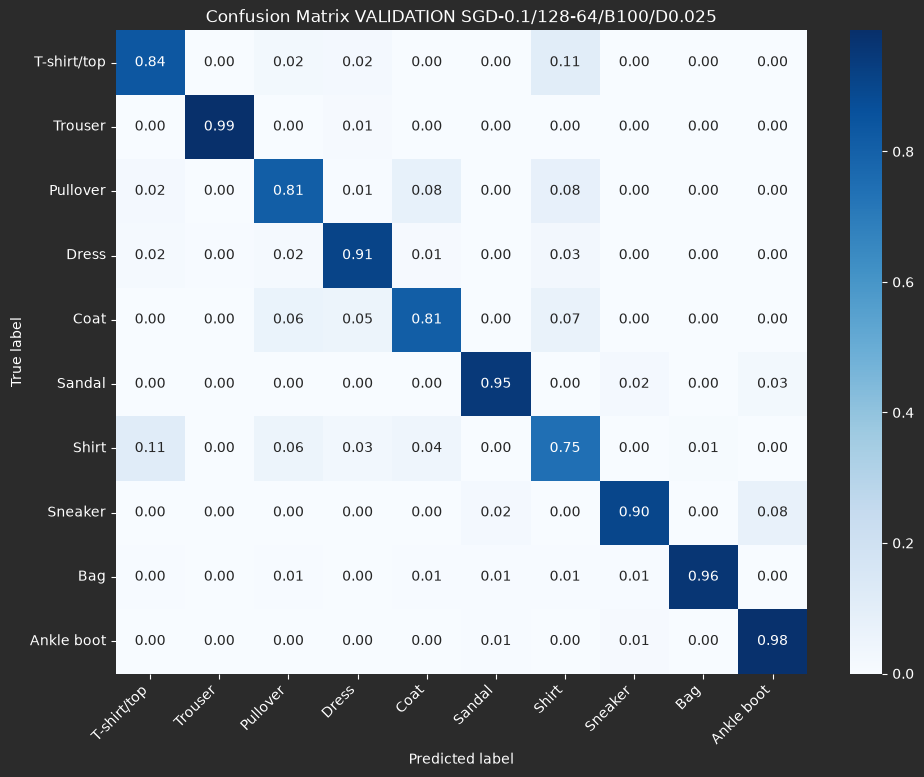

                           Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
SGD-0.1/128-64/B100/D0.025      0.174      0.327      0.934      0.888     0.882            Shirt (74.60%)             Shirt (74.54%)                   0.746                    0.745  0.046             0.283              0.252

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0.025: 0.8822
Max Valid Accu     -> SGD-0.1/128-64/B100/D0.025: 0.8885
Best Test Worst-Class Recall -> SGD-0.1/128-64/B100/D0.025: Shirt (74.60%)
Best Valid Worst-Class Recall -> SGD-0.1/128-64/B100/D0.025: Shirt (74.54%)
Min Test CM Deviation  -> SGD-0.1/128-64/B100/D0.025: 0.2832
Min Valid CM Deviation -> SGD-0.1/128-64/B100/D0.025: 0.2522
Min abs Generalization Gap -> SGD-0.1/128-64/B100/D0.025: 0.04562002420425415
Max abs Generalization Gap -> SGD-0.1/128-64/B100/D0.02

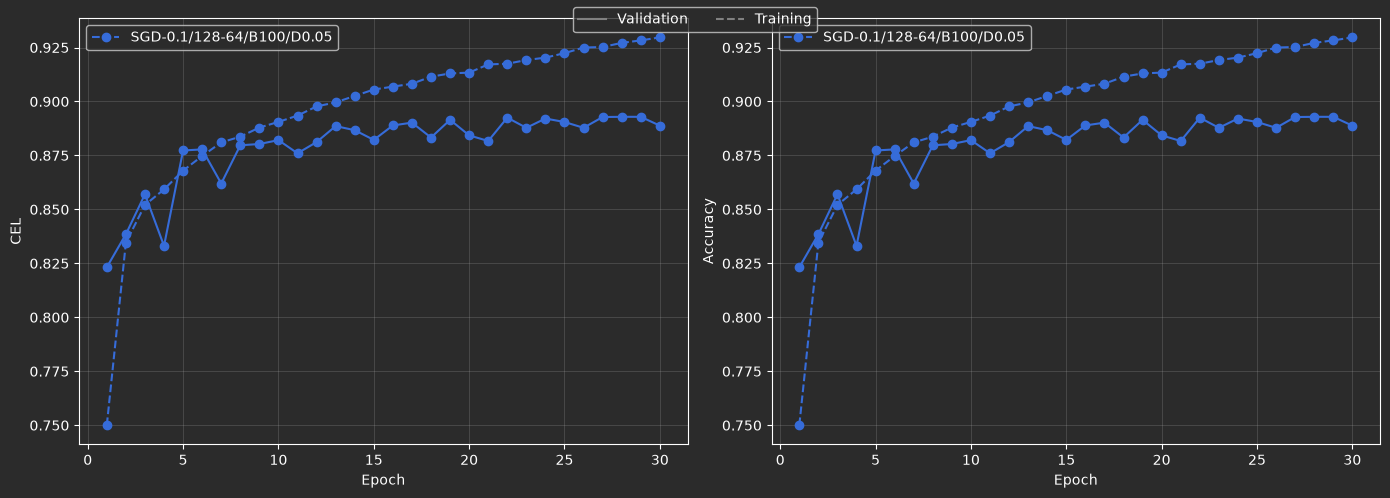

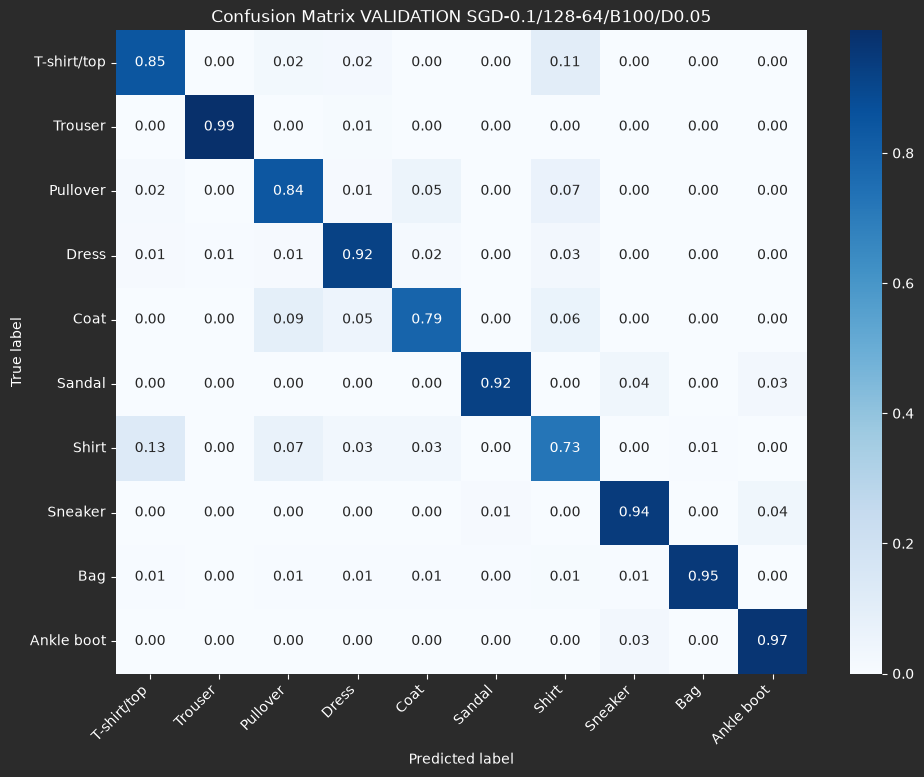

                          Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
SGD-0.1/128-64/B100/D0.05      0.185      0.318      0.930      0.889     0.887            Shirt (72.10%)             Shirt (72.51%)                   0.721                    0.725  0.041             0.277              0.255

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0.05: 0.8866
Max Valid Accu     -> SGD-0.1/128-64/B100/D0.05: 0.8888
Best Test Worst-Class Recall -> SGD-0.1/128-64/B100/D0.05: Shirt (72.10%)
Best Valid Worst-Class Recall -> SGD-0.1/128-64/B100/D0.05: Shirt (72.51%)
Min Test CM Deviation  -> SGD-0.1/128-64/B100/D0.05: 0.2769
Min Valid CM Deviation -> SGD-0.1/128-64/B100/D0.05: 0.2554
Min abs Generalization Gap -> SGD-0.1/128-64/B100/D0.05: 0.04089999198913574
Max abs Generalization Gap -> SGD-0.1/128-64/B100/D0.05: 0.04089

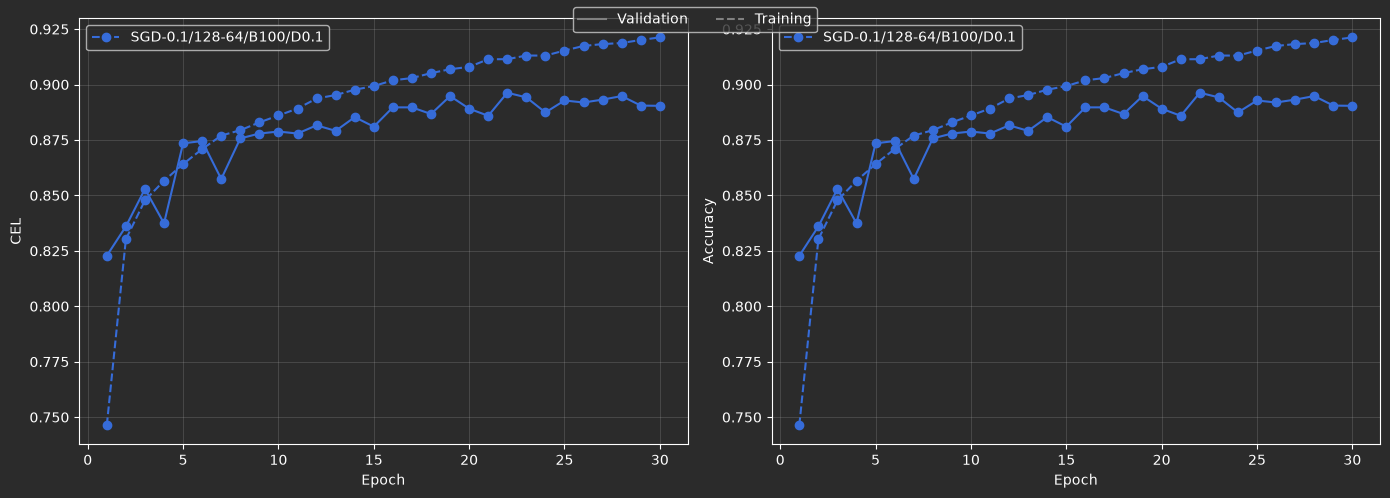

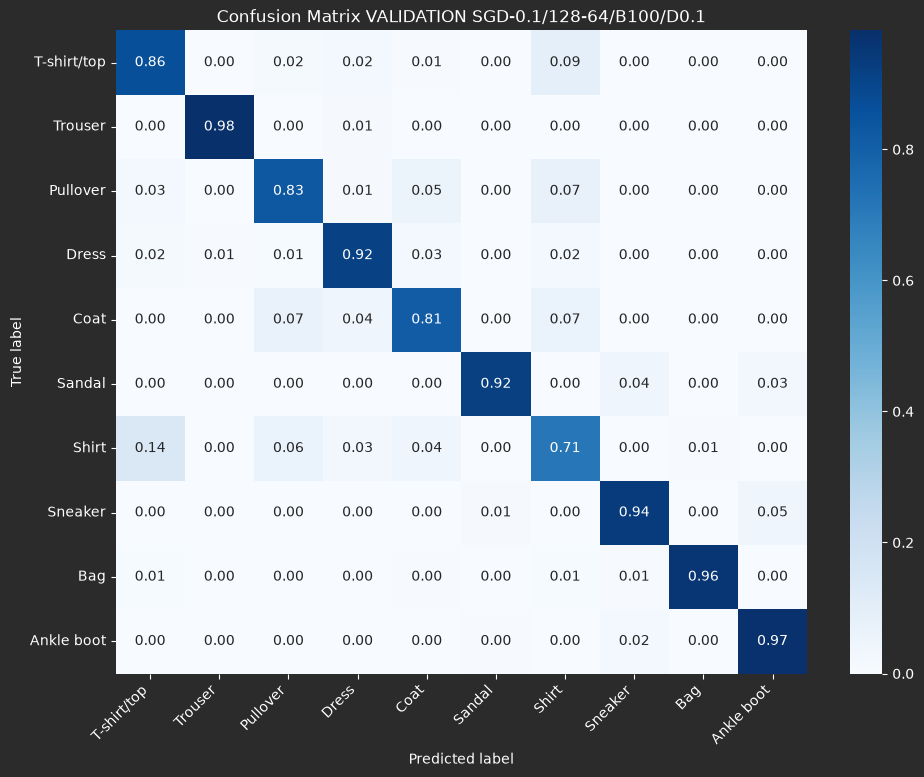

                         Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
SGD-0.1/128-64/B100/D0.1      0.209      0.308      0.921      0.890     0.888            Shirt (71.20%)             Shirt (71.06%)                   0.712                    0.711  0.031             0.269              0.251

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0.1: 0.8880
Max Valid Accu     -> SGD-0.1/128-64/B100/D0.1: 0.8904
Best Test Worst-Class Recall -> SGD-0.1/128-64/B100/D0.1: Shirt (71.20%)
Best Valid Worst-Class Recall -> SGD-0.1/128-64/B100/D0.1: Shirt (71.06%)
Min Test CM Deviation  -> SGD-0.1/128-64/B100/D0.1: 0.2687
Min Valid CM Deviation -> SGD-0.1/128-64/B100/D0.1: 0.2506
Min abs Generalization Gap -> SGD-0.1/128-64/B100/D0.1: 0.03086000680923462
Max abs Generalization Gap -> SGD-0.1/128-64/B100/D0.1: 0.030860006809234

In [3]:
viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)